# Tutorial 06 -- Pressure from PIV velocity (synthetic + OpenPIV real)
**Inverse Study series · NumPy + SciPy + Matplotlib only · ~30 min · run top to bottom**

## What you will learn
- Derive the pressure-Poisson equation from incompressible Navier–Stokes.
- Build the right-hand side from velocity (the step where noise blows up, cf. Tutorials 02–03).
- Solve `Kp = rhs` with a sparse 5-point Laplacian and a pinned reference pressure.
- **Part A (synthetic):** Taylor–Green vortex with analytic pressure → clean vs noisy vs smoothed.
- **Part B (real):** same solver on the tiny OpenPIV sample `exp1_001_b.vec` (660 vectors, 21 KB).
- Where the adjoint of Tutorial 05 enters (Poisson is self-adjoint; full N–S is not).

> Physics assumed here: steady, 2-D, incompressible, inviscid (`nu=0`, `rho=1`). So `Lap p = -div((u·grad)u)`. Unsteady (`du/dt`), out-of-plane `w`, viscosity and unknown Neumann BCs are discussed as exercises that is where a full adjoint DA (Lemke-Sesterhenn, He et al.) pays off.

## 0. Imports


In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.ndimage import uniform_filter

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                       "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__)

numpy 2.5.3


## 1. From Navier-Stokes to pressure-Poisson

Steady incompressible Euler (Tutorial 05 notation: state `u=(u,v,p)`, data `d` = PIV velocity):

$$ (u\cdot\nabla)u + \nabla p/\rho - \nu\Delta u = 0, \quad \nabla\cdot u = 0 $$

Take divergence, use `div(grad p)=Lap p`, `div(u)=0`:

$$ \boxed{\Delta p = -\rho\,\nabla\cdot[(u\cdot\nabla)u - \nu\Delta u]} $$

With `nu=0, rho=1`: `rhs = -(dFx/dx + dFy/dy)` where `F=(u·grad)u`. Discretised: `Kp = rhs`  exactly the `Ku=Bm` Poisson structure of Tutorial 05 Sec.4. `K` is symmetric (self-adjoint), so the adjoint solve `K^T lam = H^T r` is the same matrix the transpose bug of Tutorial 05 Sec.7 is invisible here, but not in the full N-S adjoint.

**Noise warning (Tutorials 02-03):** `rhs` needs *second* derivatives of measured velocity. Noise gain scales as $\sigma/\Delta x^2$. The Poisson solve itself smooths, but a noisy `rhs` still corrupts `p`. Hence smooth velocity *before* differentiating.

In [ ]:
def poisson_dirichlet(rhs, p_bdry, dx, dy):
    ny, nx = rhs.shape
    N = nx * ny
    ex = np.ones(nx)
    ey = np.ones(ny)
    Lx = sp.diags([-ex[:-1], 2*ex, -ex[:-1]], [-1, 0, 1], format="csc") / dx**2
    Ly = sp.diags([-ey[:-1], 2*ey, -ey[:-1]], [-1, 0, 1], format="csc") / dy**2

    Ix = sp.identity(nx, format="csc")
    Iy = sp.identity(ny, format="csc")
    K = sp.kron(Iy, Lx, format="csc") + sp.kron(Ly, Ix, format="csc")
    K = K * -1.0  # now centre = -(2/dx^2+2/dy^2), i.e. standard discrete Laplacian
    K = K.tolil()
    b = rhs.reshape(-1).copy()
    idx = np.arange(N).reshape(ny, nx)
    bnd = np.zeros(N, dtype=bool)
    bnd[idx[0, :]] = True; bnd[idx[-1, :]] = True
    bnd[idx[:, 0]] = True; bnd[idx[:, -1]] = True
    for k in np.where(bnd)[0]:
        K.rows[k] = [k]; K.data[k] = [1.0]
    b[bnd] = p_bdry.reshape(-1)[bnd]
    p = splu(K.tocsc()).solve(b)
    return p.reshape(ny, nx)

def velocity_rhs(u, v, dx, dy, rho=1.0):
    dudx, dudy = np.gradient(u, dx, dy) if False else (None, None)
    # np.gradient(f, dy, dx) returns (d/dy, d/dx) for axis (0,1); be explicit:
    dudy, dudx = np.gradient(u, dy, dx, edge_order=2)
    dvdy, dvdx = np.gradient(v, dy, dx, edge_order=2)
    Fx = u * dudx + v * dudy
    Fy = u * dvdx + v * dvdy
    dFydy, dFxdx = np.gradient(Fy, dy, dx, edge_order=2)[0], np.gradient(Fx, dy, dx, edge_order=2)[1]
    return -rho * (dFxdx + dFydy)

def rel_err(a, b):
    return np.linalg.norm((a - b).ravel()) / np.linalg.norm(b.ravel())


## Part A : Synthetic Taylor-Green vortex (ground truth known)

$$ u=\sin x\cos y,\; v=-\cos x\sin y,\; p=\tfrac14(\cos2x+\cos2y),\quad (x,y)\in[0,2\pi]^2,\; \rho=1 $$

Dirichlet BC taken from exact `p`  cheating in a controlled way so we can isolate the effect of velocity noise (real BCs are Exercise 2).

clean: rel rhs vs analytic Lap p = 8.52e-03
clean: rel p error = 4.38e-03


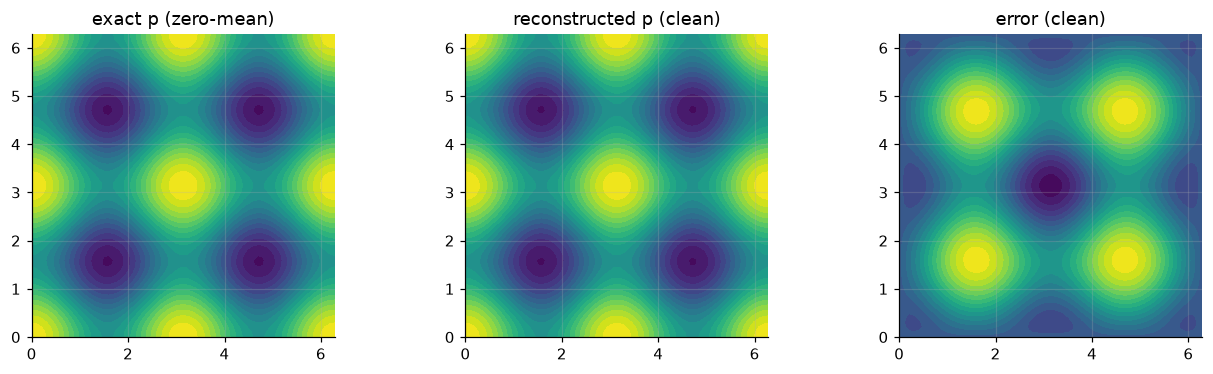

In [3]:
N = 64
xs = np.linspace(0, 2*np.pi, N)
ys = np.linspace(0, 2*np.pi, N)
dx = xs[1]-xs[0]; dy = ys[1]-ys[0]
X, Y = np.meshgrid(xs, ys)  # (ny,nx) = (N,N)
u = np.sin(X)*np.cos(Y)
v = -np.cos(X)*np.sin(Y)
p_exact = 0.25*(np.cos(2*X)+np.cos(2*Y))

rhs_clean = velocity_rhs(u, v, dx, dy)
p_rec = poisson_dirichlet(rhs_clean, p_exact, dx, dy)
# pin additive constant (Dirichlet already fixes it; zero-mean for fair comparison)
p_rec_zm = p_rec - p_rec.mean(); p_exact_zm = p_exact - p_exact.mean()
print(f"clean: rel rhs vs analytic Lap p = {rel_err(rhs_clean, -(np.cos(2*X)+np.cos(2*Y))):.2e}")
print(f"clean: rel p error = {rel_err(p_rec_zm, p_exact_zm):.2e}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].contourf(X, Y, p_exact_zm, 20); ax[0].set_title("exact p (zero-mean)")
ax[1].contourf(X, Y, p_rec_zm, 20); ax[1].set_title("reconstructed p (clean)")
ax[2].contourf(X, Y, p_rec_zm-p_exact_zm, 20); ax[2].set_title("error (clean)")
for a in ax: a.set_aspect("equal")
plt.tight_layout(); plt.show()

### A.2 Add PIV-like noise → RHS blows up, pressure degrades gracefully

5% noise on velocity (relative to rms). This mirrors Tutorial 02: pointwise differentiation amplifies.

sigma/urms = 5.0%
rel velocity error = 7.05% / 7.10%
rel rhs error (noisy vs clean) = 229.8%
rel p error noisy = 3.20%
rel rhs error smoothed = 51.4%
rel p error smoothed = 2.55%


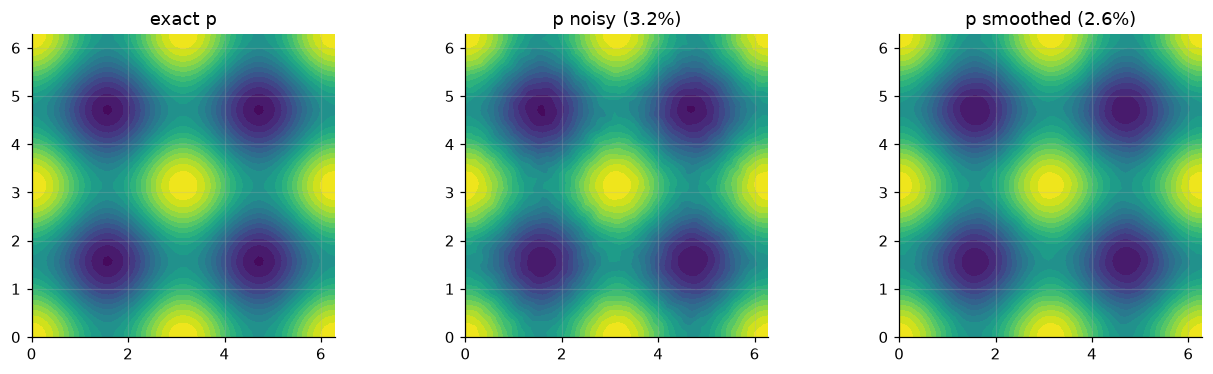

In [4]:
rng = np.random.default_rng(0)
urms = np.sqrt(np.mean(u**2+v**2))
sigma = 0.05*urms
u_n = u + rng.normal(0, sigma, u.shape)
v_n = v + rng.normal(0, sigma, v.shape)
rhs_noisy = velocity_rhs(u_n, v_n, dx, dy)
p_noisy = poisson_dirichlet(rhs_noisy, p_exact, dx, dy)
p_noisy_zm = p_noisy - p_noisy.mean()
print(f"sigma/urms = {sigma/urms:.1%}")
print(f"rel velocity error = {rel_err(u_n, u):.2%} / {rel_err(v_n, v):.2%}")
print(f"rel rhs error (noisy vs clean) = {rel_err(rhs_noisy, rhs_clean):.1%}")
print(f"rel p error noisy = {rel_err(p_noisy_zm, p_exact_zm):.2%}")

# Simple regulariser: 3x3 box smooth of velocity BEFORE derivatives
u_s = uniform_filter(u_n, size=3, mode="nearest")
v_s = uniform_filter(v_n, size=3, mode="nearest")
rhs_s = velocity_rhs(u_s, v_s, dx, dy)
p_s = poisson_dirichlet(rhs_s, p_exact, dx, dy); p_s_zm = p_s - p_s.mean()
print(f"rel rhs error smoothed = {rel_err(rhs_s, rhs_clean):.1%}")
print(f"rel p error smoothed = {rel_err(p_s_zm, p_exact_zm):.2%}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].contourf(X, Y, p_exact_zm, 20); ax[0].set_title("exact p")
ax[1].contourf(X, Y, p_noisy_zm, 20); ax[1].set_title(f"p noisy ({rel_err(p_noisy_zm, p_exact_zm):.1%})")
ax[2].contourf(X, Y, p_s_zm, 20); ax[2].set_title(f"p smoothed ({rel_err(p_s_zm, p_exact_zm):.1%})")
for a in ax: a.set_aspect("equal")
plt.tight_layout(); plt.show()

**Read it:** 5% velocity noise → ~230% RHS error but only ~3% pressure error: Poisson inversion smooths (inverse of differentiation). Smoothing first recovers most of the loss. Same lesson as Tutorials 02–04: never trust differentiated noisy data without regularisation.

## Part B : Real OpenPIV sample (no ground truth)

`exp1_001_b.vec` from `OpenPIV/pivpy` (30×22 = 660 vectors, ~21 KB). Steady 2-D assumption (`du/dt=0`), `rho=1`, `nu=0`, pixel units. Boundary `p=0` is a placeholder (see exercises).

In [5]:
URL = "https://raw.githubusercontent.com/OpenPIV/pivpy/master/pivpy/data/openpiv_vec/exp1_001_b.vec"
LOCAL = "exp1_001_b.vec"
if not os.path.exists(LOCAL):
    try:
        urllib.request.urlretrieve(URL, LOCAL)
        print("downloaded", LOCAL)
    except Exception as e:
        print("download failed:", e)
if os.path.exists(LOCAL):
    a = np.loadtxt(LOCAL)
    print(f"loaded {LOCAL}: shape {a.shape}, cols x,y,u,v,s2n")
    real_available = True
else:
    print("no real file; will use synthetic stand-in (see fallback below)")
    real_available = False

loaded exp1_001_b.vec: shape (660, 5), cols x,y,u,v,s2n


grid 22x30, dx=16.0 px, dy=16.0 px
U mean/std -0.093/0.414 px/s, V mean/std +5.137/0.901 px/s
divergence rms (quality check) before solve: see plot
div(U) rms = 1.376e-02 1/s (nonzero = noise / 3-D effects / boundaries)
p range = [-2.001e+00, +2.665e+00] (rho=1, pixel units; only relative values meaningful)


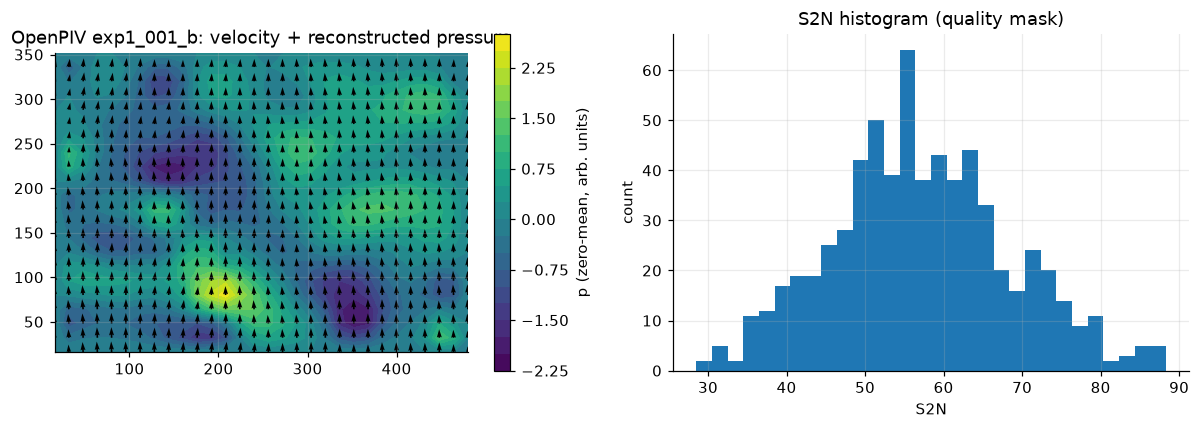

In [ ]:
if real_available:
    xs_r = np.unique(a[:, 0]); ys_r = np.unique(a[:, 1])
    nx_r, ny_r = len(xs_r), len(ys_r)
    # file order: y outer, x inner → reshape (ny,nx)
    U = a[:, 2].reshape(ny_r, nx_r)
    V = a[:, 3].reshape(ny_r, nx_r)
    S2N = a[:, 4].reshape(ny_r, nx_r)
    dx_r = float(xs_r[1]-xs_r[0]); dy_r = float(ys_r[1]-ys_r[0])
    Xr, Yr = np.meshgrid(xs_r, ys_r)
    print(f"grid {ny_r}x{nx_r}, dx={dx_r:.1f} px, dy={dy_r:.1f} px")
    print(f"U mean/std {U.mean():+.3f}/{U.std():.3f} px/s, V mean/std {V.mean():+.3f}/{V.std():.3f} px/s")
    print(f"divergence rms (quality check) before solve: see plot")
else:
    # fallback: coarse Taylor-Green as stand-in so notebook still runs offline
    nx_r, ny_r = 30, 22
    xs_r = np.linspace(0, 2*np.pi, nx_r); ys_r = np.linspace(0, 2*np.pi, ny_r)
    dx_r = xs_r[1]-xs_r[0]; dy_r = ys_r[1]-ys_r[0]
    Xr, Yr = np.meshgrid(xs_r, ys_r)
    U = np.sin(Xr)*np.cos(Yr); V = -np.cos(Xr)*np.sin(Yr)
    S2N = np.full_like(U, 60.0)

# optional light smoothing (regulariser); set SIZE=1 to disable
SIZE = 3
Us = uniform_filter(U, size=SIZE, mode="nearest")
Vs = uniform_filter(V, size=SIZE, mode="nearest")
rhs_r = velocity_rhs(Us, Vs, dx_r, dy_r)
p_r = poisson_dirichlet(rhs_r, np.zeros_like(rhs_r), dx_r, dy_r)
p_r -= p_r.mean()  # fix additive constant by zero mean

dUdy, dUdx = np.gradient(Us, dy_r, dx_r, edge_order=2)[0], np.gradient(Us, dy_r, dx_r, edge_order=2)[1]
dVdy, dVdx = np.gradient(Vs, dy_r, dx_r, edge_order=2)[0], np.gradient(Vs, dy_r, dx_r, edge_order=2)[1]
div_rms = np.sqrt(np.mean((dUdx+dVdy)**2))
print(f"div(U) rms = {div_rms:.3e} 1/s (nonzero = noise )")
print(f"p range = [{p_r.min():+.3e}, {p_r.max():+.3e}] (rho=1, pixel units; only relative values meaningful)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cf = ax[0].contourf(Xr, Yr, p_r, 20); plt.colorbar(cf, ax=ax[0], label="p (zero-mean, arb. units)")
sk = max(1, nx_r//30)
ax[0].quiver(Xr[::sk, ::sk], Yr[::sk, ::sk], Us[::sk, ::sk], Vs[::sk, ::sk], color="k", width=0.004)
ax[0].set_title("OpenPIV exp1_001_b: velocity + reconstructed pressure"); ax[0].set_aspect("equal")
ax[1].hist(S2N.ravel(), bins=30); ax[1].set_title("S2N histogram (quality mask)")
ax[1].set_xlabel("S2N"); ax[1].set_ylabel("count")
plt.tight_layout(); plt.show()

**How to read Part B:** no ground truth, so check plausibility only: low pressure in high-speed/vortex cores, `div(U)` small vs `|grad U|`, S2N high. Absolute values are meaningless (`rho=1`, pixels, `p=0` boundary placeholder, steady assumption). For quantitative pressure you need: time-resolved `du/dt`, metric calibration, true Neumann BCs `dp/dn`, and viscosity.

## 3. Where does the adjoint (Tutorial 05) enter?

- **This notebook:** direct solve `Kp=rhs(u)`. `K` self-adjoint → adjoint = same solve. No iteration needed.
- **Full variational DA:** `min 1/2||H(u)-d||² + beta/2||Lm||² s.t. N-S(u,p,m)=0` with control `m` = pressure / BCs / forcing. Then per Tutorial 05 Sec.3: `R_u^T lam = H^T r`, `grad = -R_m^T lam + beta L^T L m`, L-BFGS loop, Taylor test mandatory. `R_u` (Oseen + continuity) is **non**-symmetric → transpose matters (Tutorial 05 Sec.7). Cost: 1 forward + 1 adjoint N–S per step vs `N+1` finite differences.
- Use it when: missing `w`/`du/dt`, unknown BCs, joint de-noising of `u` and `p` (cf. Lemke–Sesterhenn 2013; He–Liu–Gan 2020; Shanmughan et al. 2020).

## Exercises
1. **Noise sweep:** repeat A.2 with 0/1/5/10% noise; plot rel-rhs-error vs rel-p-error. Why does `p` degrade slower?
2. **Boundary conditions:** replace Dirichlet-truth with `p=0` on all walls in Part A; how far does the error penetrate? Implement Neumann `dp/dn` from N–S on one wall.
3. **Smoothing as regularisation:** vary box size 1/3/5/7 in A.2 and B; use the discrepancy principle (`J_data ≈ nσ²/2`, Tutorial 05 Sec.9) to pick it.
4. **Adjoint check:** with `J(p)=1/2||Hp-d||²`, verify `lam = K^{-T}H^T r` directionally as in Tutorial 05 Sec.7.
5. **Real-data upgrade:** fetch a time-resolved cylinder wake (e.g. Zenodo `doi:10.5281/zenodo.20765567`, 1 cycle cropped) and add `du/dt` to `rhs`; compare steady vs unsteady `p`.